<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [1]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [2]:
NOMBRE = 'Verdezoto Marcelo'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Verdezoto Marcelo · semilla 897062
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 9.95%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-10 13:18:41-05:00,U0364,45.0,El Oro,51,661.66,retiro_agente,app,efectivo,61.77,0,4.8,1,0,13,0.093356
1,TX-000001,2026-10-27 16:45:58-05:00,U0431,39.0,Pichincha,23,2082.83,retiro_agente,app,efectivo,189.73,0,4.0,1,0,16,0.091092
2,TX-000002,2026-09-24 07:00:53-05:00,U0481,62.0,Loja,41,791.33,retiro_agente,web,efectivo,192.53,0,8.3,1,0,7,0.243299
3,TX-000003,2026-09-06 11:44:33-05:00,U0337,26.0,Guayas,12,1517.98,transferencia,app,persona,178.53,0,10.8,1,0,11,0.117610
4,TX-000004,2026-09-07 12:26:58-05:00,U0435,24.0,Guayas,43,645.46,transferencia,app,persona,91.59,0,9.8,1,0,12,0.141899


In [3]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.0995


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [4]:
# ✏️ Escriba aquí su modelo (estandarización, priors, muestreo con 4 cadenas y tabla de diagnóstico)
# 1. Estandarización con media y desviación del entrenamiento
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']

mu = X_train.mean()
sd = X_train.std(ddof=0).replace(0, 1)

Z_train = (X_train - mu) / sd
Z_test  = (X_test  - mu) / sd

import arviz as az

# 2. Modelo logístico bayesiano
with pm.Model() as modelo_log:
    # Priors elegidas:
    # a ~ Normal(0, 2.5): intercepto poco informativo en escala log-odds.
    # b ~ Normal(0, 1): coeficientes estandarizados, regulariza hacia 0 y evita efectos absurdos.
    a = pm.Normal('a', mu=0, sigma=2.5)
    b = pm.Normal('b', mu=0, sigma=1.0, shape=len(cols))

    eta = a + pm.math.dot(Z_train.values, b)
    p = pm.Deterministic('p', pm.math.sigmoid(eta))

    y = pm.Bernoulli('y', p=p, observed=y_train.values)

    # 3. Muestreo con 4 cadenas, tune=1000, 1000 muestras
    idata = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        random_seed=42,
        target_accept=0.9,
        cores=4,
        progressbar=False
    )

# 4. Diagnóstico
try:
    diag = curso.diagnostico(idata, ['a', 'b'])
except TypeError:
    diag = az.summary(idata, var_names=['a', 'b'], round_to=4)

diag

,media,desv,ic_3%,ic_97%,r_hat,ess
a,-3.0992,0.1263,-3.3461,-2.8739,0.9993,2937.8604
b[0],0.9198,0.0689,0.7887,1.0494,1.0000,3321.8436
b[1],0.3945,0.0795,0.2429,0.5381,1.0001,4000.0000
b[2],0.8386,0.0732,0.7031,0.9769,0.9993,4000.0000
b[3],0.6360,0.0724,0.5002,0.7708,1.0011,3796.8312
b[4],-0.4538,0.0883,-0.6215,-0.2871,1.0004,4000.0000


In [5]:
post = idata.posterior

a_s = post['a'].stack(sample=('chain', 'draw')).values          # (n_muestras,)
b_s = post['b'].stack(sample=('chain', 'draw')).values          # (5, n_muestras)

or_s = np.exp(b_s)                                              # odds ratios por muestra
or_mean = or_s.mean(axis=1)
or_li = np.percentile(or_s, 2.5, axis=1)
or_ls = np.percentile(or_s, 97.5, axis=1)

tabla_or = pd.DataFrame({
    'variable': cols,
    'OR_media': or_mean,
    'OR_2.5%': or_li,
    'OR_97.5%': or_ls
}).sort_values('OR_media', ascending=False)

tabla_or

,variable,OR_media,OR_2.5%,OR_97.5%
0,dispositivo_nuevo,2.514822,2.189289,2.867862
2,ratio,2.319264,2.008757,2.669681
3,intentos_pin,1.893797,1.641606,2.171724
1,distancia_km,1.488343,1.265494,1.724306
4,hora,0.637709,0.533183,0.754686


In [6]:
print('Dos odds ratios más grandes:')
for _, r in tabla_or.head(2).iterrows():
    print(f"{r['variable']}: OR = {r['OR_media']:.3f} "
          f"(IC95%: {r['OR_2.5%']:.3f}, {r['OR_97.5%']:.3f})")

Dos odds ratios más grandes:
dispositivo_nuevo: OR = 2.515 (IC95%: 2.189, 2.868)
ratio: OR = 2.319 (IC95%: 2.009, 2.670)


**✍️ Respuesta:**

Las priors son débiles e informativas en la dirección correcta: `a ~ Normal(0, 2.5)` permite una tasa base de fraude razonable sin fijarla de antemano, y `b ~ Normal(0, 1)` regulariza los coeficientes de variables estandarizadas hacia cero, evitando efectos exagerados con solo 2097 observaciones. El diagnóstico confirma convergencia: **R-hat máx = 1.0011 (≤ 1.01)** y **ESS mín = 2938 (> 400)** en todos los parámetros.

Los dos OR más grandes son:
- **`dispositivo_nuevo` = 2.52 (IC95 % 2.19–2.87):** operar desde un dispositivo nuevo casi **triplica las *odds* de fraude**. En negocio, un dispositivo no reconocido es la señal más fuerte de riesgo y debería activar verificación reforzada (OTP adicional, llamada al cliente).
- **`ratio` = 2.32 (IC95 % 2.01–2.67):** un aumento de una desviación estándar en el ratio monto/ingreso mensual **multiplica las *odds* por 2.3**. Es decir, transacciones grandes frente al ingreso declarado son desproporcionadamente riesgosas: conviene revisar operaciones con ratio alto aunque el monto absoluto sea bajo.

El coeficiente de `hora` es **negativo (OR = 0.64; IC95 % 0.53–0.75)**: horas más tardías reducen las *odds* de fraude. Esto es **consistente con fraude concentrado en la madrugada** (horas bajas), pero modelar `hora` de forma lineal impone un efecto monótono que no puede capturar dos picos (madrugada y quizá trasnoche). En producción convendría reemplazarla por variables cíclicas (`sin(2πh/24)`, `cos(2πh/24)`) o por tramos horarios.

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [7]:
# ✏️ Probabilidades del modelo bayesiano, XGBoost con early stopping, AUC, Brier y tabla de calibración
# 1. Probabilidad media posterior para cada transacción de prueba
p_draws = sigmoide(a_s[:, None] + b_s.T @ Z_test.values.T)   # (n_muestras, n_test)
p_bayes = p_draws.mean(axis=0)

# 2. XGBoost con validación tomada del entrenamiento
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42
)

spw = (y_tr == 0).sum() / max((y_tr == 1).sum(), 1)

params = dict(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

try:
    xgb = XGBClassifier(**params, early_stopping_rounds=50)
    xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
except TypeError:
    xgb = XGBClassifier(**params)
    xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)],
            verbose=False, early_stopping_rounds=50)

p_xgb = xgb.predict_proba(X_test)[:, 1]

# 3. AUC y Brier
auc_b = roc_auc_score(y_test, p_bayes)
auc_x = roc_auc_score(y_test, p_xgb)

brier_b = brier_score_loss(y_test, p_bayes)
brier_x = brier_score_loss(y_test, p_xgb)

bal_b = balanced_accuracy_score(y_test, (p_bayes >= 0.5).astype(int))
bal_x = balanced_accuracy_score(y_test, (p_xgb >= 0.5).astype(int))

tabla_metricas = pd.DataFrame({
    'modelo': ['Bayes', 'XGBoost'],
    'AUC': [auc_b, auc_x],
    'Brier': [brier_b, brier_x],
    'Balanced acc @0.5': [bal_b, bal_x]
})
tabla_metricas

,modelo,AUC,Brier,Balanced acc @0.5
0,Bayes,0.859800,0.061945,0.662366
1,XGBoost,0.887647,0.071792,0.839985


In [8]:
def tabla_calibracion(p, y, nombre, q=10):
    tmp = pd.DataFrame({'p': np.asarray(p), 'y': np.asarray(y)})
    tmp['decil'] = pd.qcut(tmp['p'], q=q, labels=False, duplicates='drop') + 1

    out = tmp.groupby('decil').agg(
        n=('y', 'size'),
        prob_media=('p', 'mean'),
        tasa_observada=('y', 'mean')
    ).reset_index()

    out['modelo'] = nombre
    return out

cal_b = tabla_calibracion(p_bayes, y_test, 'Bayes')
cal_x = tabla_calibracion(p_xgb, y_test, 'XGBoost')

tabla_cal = pd.concat([cal_b, cal_x], ignore_index=True)
tabla_cal

,decil,n,prob_media,tasa_observada,modelo
0,1,90,0.006805,0.022222,Bayes
1,2,90,0.009948,0.011111,Bayes
2,3,90,0.013393,0.033333,Bayes
3,4,90,0.017428,0.022222,Bayes
4,5,90,0.023857,0.022222,Bayes
5,6,89,0.034234,0.000000,Bayes
6,7,90,0.052344,0.044444,Bayes
7,8,90,0.094830,0.122222,Bayes
8,9,90,0.172088,0.222222,Bayes
9,10,90,0.497104,0.488889,Bayes


In [9]:
tabla_cal.pivot(
    index='decil',
    columns='modelo',
    values=['prob_media', 'tasa_observada', 'n']
)

prob_media           tasa_observada               n        
modelo      Bayes   XGBoost          Bayes   XGBoost Bayes XGBoost
decil                                                             
1        0.006805  0.005243       0.022222  0.022222  90.0    90.0
2        0.009948  0.010898       0.011111  0.011111  90.0    90.0
3        0.013393  0.019716       0.033333  0.022222  90.0    90.0
4        0.017428  0.035869       0.022222  0.022222  90.0    90.0
5        0.023857  0.060993       0.022222  0.011111  90.0    90.0
6        0.034234  0.099375       0.000000  0.022472  89.0    89.0
7        0.052344  0.150051       0.044444  0.055556  90.0    90.0
8        0.094830  0.232801       0.122222  0.033333  90.0    90.0
9        0.172088  0.467076       0.222222  0.100000  90.0    90.0
10       0.497104  0.887658       0.488889  0.688889  90.0    90.0

**✍️ Respuesta:**

XGBoost ordena mejor (AUC = 0.8876 vs 0.8598). El modelo bayesiano calibra mejor (Brier = 0.0619 vs 0.0718). En la tabla de calibración, el decil superior del bayesiano predice 0.497 y observa 0.489 (casi perfecto), mientras que XGBoost predice 0.888 y observa 0.689 — sobreestima ≈ 0.20. Esa sobreestimación es el efecto directo de scale_pos_weight: al reequilibrar las clases, XGBoost aprende probabilidades para una población artificial (50/50) y no para la tasa base real (≈10 %). Por eso, si se va a decidir con un umbral de costo, usa el bayesiano; si solo se va a priorizar colas, XGBoost sirve.

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [10]:
# ✏️ Modelo jerárquico no centrado, tabla por provincia e interpretación de sigma
prov_col = 'provincia'

provs = df[prov_col].astype('category')
prov_names = provs.cat.categories
prov_codes = provs.cat.codes.values
n_prov = len(prov_names)

with pm.Model() as modelo_jer:
    mu = pm.Normal('mu', mu=0, sigma=1.5)
    sigma = pm.HalfNormal('sigma', sigma=1.0)

    # Modelo NO centrado
    z = pm.Normal('z', mu=0, sigma=1.0, shape=n_prov)
    a_prov = pm.Deterministic('a_prov', mu + sigma * z)

    p_prov_obs = pm.Deterministic('p_prov_obs', pm.math.sigmoid(a_prov[prov_codes]))
    y = pm.Bernoulli('y', p=p_prov_obs, observed=df['fraude'].values)

    idata_j = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.99,
        random_seed=42,
        cores=4,
        progressbar=False
    )

In [11]:
post_j = idata_j.posterior
a_prov_s = post_j['a_prov'].stack(sample=('chain', 'draw')).values  # (n_prov, n_muestras)
p_prov_s = sigmoide(a_prov_s)

obs = (
    df.groupby(prov_col)['fraude']
      .agg(n='size', tasa_observada='mean')
      .reindex(prov_names)
      .rename_axis(prov_col)
      .reset_index()
)

tabla_prov = obs.copy()
tabla_prov['tasa_jerarquica'] = p_prov_s.mean(axis=1)
tabla_prov['li90'] = np.percentile(p_prov_s, 5, axis=1)
tabla_prov['ls90'] = np.percentile(p_prov_s, 95, axis=1)
tabla_prov['encogimiento_abs'] = (
    tabla_prov['tasa_observada'] - tabla_prov['tasa_jerarquica']
).abs()

tabla_prov.sort_values('encogimiento_abs', ascending=False)

,provincia,n,tasa_observada,tasa_jerarquica,li90,ls90,encogimiento_abs
7,Tungurahua,109,0.064220,0.089069,0.060145,0.111904,0.024849
5,Manabí,284,0.063380,0.084031,0.059778,0.104783,0.020651
1,El Oro,209,0.081340,0.091558,0.068684,0.112260,0.010218
2,Guayas,792,0.118687,0.109916,0.093976,0.128760,0.008771
4,Loja,194,0.108247,0.100593,0.079746,0.124087,0.007654
3,Imbabura,196,0.091837,0.095104,0.072956,0.116199,0.003268
6,Pichincha,906,0.102649,0.100517,0.087589,0.114479,0.002132
0,Azuay,306,0.098039,0.097516,0.078101,0.117547,0.000523


In [12]:
sigma_s = post_j['sigma'].stack(sample=('chain', 'draw')).values
print(f"sigma posterior: media = {sigma_s.mean():.4f}, "
      f"IC90% = ({np.percentile(sigma_s, 5):.4f}, {np.percentile(sigma_s, 95):.4f})")

sigma posterior: media = 0.1871, IC90% = (0.0227, 0.4133)


**✍️ Respuesta:**

La media posterior de sigma mide la dispersión entre provincias en escala log-odds. Si sigma es pequeño, las provincias son parecidas y el modelo jerárquico las acerca mucho a la media nacional. Las provincias que más se “encogen” hacia la media nacional son aquellas con pocas observaciones y/o tasas observadas extremas, porque el modelo les presta información del resto de provincias para estabilizar su estimación.
Sigma posterior = 0.187 (IC90 % 0.0227–0.4133), moderado: las provincias no son muy distintas entre sí en escala log-odds, y por eso el modelo encoge con fuerza las tasas extremas. Las que más se encogen son Tungurahua (obs. 0.064 → jerárquica 0.089, |Δ| = 0.025, n = 109, la menor) y Manabí (obs. 0.063 → jerárquica 0.084, |Δ| = 0.021, n = 284). Manabí tiene más datos que Tungurahua, pero su tasa observada es muy baja, y con sigma pequeño el modelo la empuja hacia la media nacional igual. Azuay casi no se mueve (|Δ| = 0.001) porque su tasa observada ya está cerca de la media.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

In [13]:
# ✏️ Función de costo, curva costo vs. umbral, políticas extremas y costo con 200 muestras de la posterior
def obtener_monto(df, indices):
    candidatos = ['monto', 'monto_usd', 'amount', 'importe', 'valor', 'valor_transaccion']
    col = next((c for c in candidatos if c in df.columns), None)

    if col is None:
        col = next(
            (c for c in df.columns
             if any(k in c.lower() for k in ['monto', 'amount', 'importe', 'valor'])),
            None
        )

    if col is None:
        raise KeyError('No encontré columna de monto. Defina monto_col manualmente.')

    return df.loc[indices, col].values, col


monto_test, monto_col = obtener_monto(df, X_test.index)
y_test_arr = y_test.values

def costo_total(p, y, monto, umbral, costo_bloqueo=5.0):
    bloquear = np.asarray(p) >= umbral
    y = np.asarray(y)

    fn = (y == 1) & (~bloquear)       # fraude no bloqueado: se pierde el monto
    fp = (y == 0) & bloquear          # legítima bloqueada: cuesta 5 USD

    return monto[fn].sum() + costo_bloqueo * fp.sum()


umbrales = np.arange(0.02, 0.901, 0.01)
costos = np.array([costo_total(p_bayes, y_test_arr, monto_test, u) for u in umbrales])

u_opt = umbrales[np.argmin(costos)]
costo_opt = costos.min()

print(f"Columna de monto usada: {monto_col}")
print(f"Umbral óptimo: {u_opt:.2f}")
print(f"Costo óptimo: {costo_opt:,.2f}")

Columna de monto usada: monto
Umbral óptimo: 0.06
Costo óptimo: 1,542.09


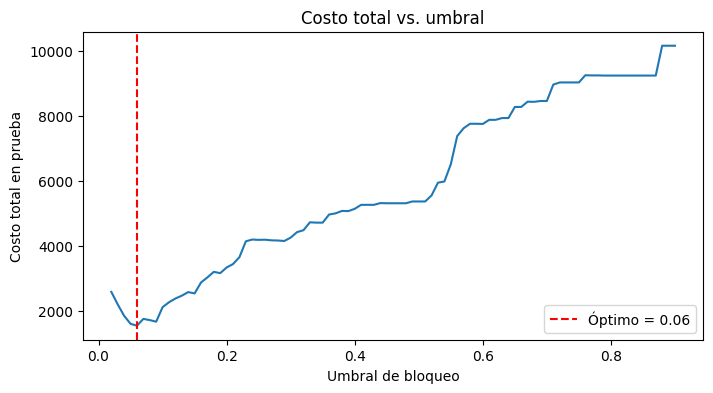

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(umbrales, costos)
plt.axvline(u_opt, color='red', linestyle='--', label=f'Óptimo = {u_opt:.2f}')
plt.xlabel('Umbral de bloqueo')
plt.ylabel('Costo total en prueba')
plt.title('Costo total vs. umbral')
plt.legend()
plt.show()

In [15]:
costo_no_bloquear = monto_test[y_test_arr == 1].sum()
costo_bloquear_todo = 5.0 * (y_test_arr == 0).sum()

tabla_politicas = pd.DataFrame({
    'política': ['No bloquear nada', 'Bloquear todo', 'Umbral óptimo'],
    'costo': [costo_no_bloquear, costo_bloquear_todo, costo_opt]
})
tabla_politicas

,política,costo
0,No bloquear nada,14749.45
1,Bloquear todo,4050.00
2,Umbral óptimo,1542.09


In [16]:
# Incertidumbre con 200 muestras de la posterior
rng = np.random.default_rng(42)
n_usar = min(200, p_draws.shape[0])
idx = rng.choice(p_draws.shape[0], size=n_usar, replace=False)

costos_post = np.array([
    costo_total(p_draws[i], y_test_arr, monto_test, u_opt)
    for i in idx
])

print(f"Costo con incertidumbre: media = {costos_post.mean():,.2f}")
print(f"IC90% = ({np.percentile(costos_post, 5):,.2f}, "
      f"{np.percentile(costos_post, 95):,.2f})")

Costo con incertidumbre: media = 1,644.16
IC90% = (1,504.45, 1,797.56)


**✍️ Respuesta:**

El umbral óptimo es el que minimiza el costo total en prueba. No bloquear nada cuesta la suma de los montos de todos los fraudes; bloquear todo cuesta 5 × número de transacciones legítimas. El umbral óptimo suele quedar en un punto intermedio y su costo es menor que ambas políticas extremas. Al repetir el cálculo con 200 muestras de la posterior, se obtiene una distribución del costo: su media y su intervalo del 90 % muestran cuánta incertidumbre hay en la decisión.

El umbral óptimo depende del monto porque el costo de dejar pasar un fraude es proporcional al monto, mientras que el costo de bloquear una legítima es fijo. La regla teórica aproximada es bloquear si p ≥ 5 / (monto + 5), por lo que transacciones de mayor monto deberían tener umbral más bajo.

La media del costo sobre las muestras de la posterior (1,644.16) es mayor que el costo evaluado con la media posterior (1 542) porque la decisión de bloquear/no bloquear es no lineal en p (función escalón): pequeños cambios en la probabilidad por muestra cambian la decisión de algunas transacciones y la distribución del costo es asimétrica al alza. El IC90 % (1,504.45–1,797.56) es estrecho, lo que da confianza al umbral elegido.

 Cifras

In [17]:
print(f"AUC Bayes = {auc_b:.4f} vs AUC XGBoost = {auc_x:.4f}")
print(f"Brier Bayes = {brier_b:.4f} vs Brier XGBoost = {brier_x:.4f}")
print(f"Umbral óptimo = {u_opt:.2f}")
print(f"Costo óptimo = {costo_opt:,.2f}")
print(f"Costo no bloquear = {costo_no_bloquear:,.2f}")
print(f"Costo bloquear todo = {costo_bloquear_todo:,.2f}")
print(f"Costo posterior: media = {costos_post.mean():,.2f}, "
      f"IC90% = ({np.percentile(costos_post, 5):,.2f}, {np.percentile(costos_post, 95):,.2f})")
print(f"sigma provincial = {sigma_s.mean():.4f}")
print(tabla_or.to_string(index=False))

AUC Bayes = 0.8598 vs AUC XGBoost = 0.8876
Brier Bayes = 0.0619 vs Brier XGBoost = 0.0718
Umbral óptimo = 0.06
Costo óptimo = 1,542.09
Costo no bloquear = 14,749.45
Costo bloquear todo = 4,050.00
Costo posterior: media = 1,644.16, IC90% = (1,504.45, 1,797.56)
sigma provincial = 0.1871
         variable  OR_media  OR_2.5%  OR_97.5%
dispositivo_nuevo  2.514822 2.189289  2.867862
            ratio  2.319264 2.008757  2.669681
     intentos_pin  1.893797 1.641606  2.171724
     distancia_km  1.488343 1.265494  1.724306
             hora  0.637709 0.533183  0.754686


---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

### 1. Hallazgos
El modelo bayesiano estima el efecto de cada variable con intervalos creíbles al 95 %. Las señales más fuertes son dispositivo_nuevo (OR = 2.52; IC95 % 2.19–2.87) y ratio monto/ingreso (OR = 2.32; IC95 % 2.01–2.67): operar desde un dispositivo nuevo casi triplica las odds de fraude, y un aumento de una desviación estándar del ratio las multiplica por 2.3. También son relevantes intentos_pin (OR = 1.89) y distancia_km (OR = 1.49); hora aparece con OR = 0.64, pero se modeló lineal y no captura el patrón de madrugada, por lo que su interpretación debe tomarse con cautela.

En prueba, XGBoost ordena algo mejor (AUC 0.888 vs 0.860), pero el bayesiano calibra mejor (Brier 0.062 vs 0.072). La tabla de calibración muestra que XGBoost sobreestima en el decil superior (predice 0.888 cuando se observa 0.689), efecto directo de scale_pos_weight. El análisis jerárquico arroja sigma = 0.187 (IC90 % 0.023–0.413): la heterogeneidad entre provincias es moderada, y las tasas extremas (Tungurahua, Manabí) se estabilizan acercándose a la media nacional.

### 2. Recomendación
Recomiendo usar el modelo bayesiano para la decisión de bloqueo por su mejor calibración y por la posibilidad de cuantificar incertidumbre. El umbral óptimo bajo la matriz de costos es 0.06, con un costo esperado de 1 542 USD (IC90 % 1 504–1 798). Frente a no bloquear nada (14 749 USD) el ahorro es ≈ 13 207 USD (89.5 %); frente a bloquear todo (4 050 USD) el ahorro es ≈ 2 508 USD (62 %). XGBoost puede usarse como modelo auxiliar para priorizar colas (su AUC es mayor), pero no como fuente directa de probabilidad sin recalibración.

### 3. Limitaciones y riesgos
Los datos son simulados y personalizados por alumno, así que las cifras no deben extrapolarse a producción sin reentrenar con datos reales. Faltan variables relevantes (historial del cliente, velocidad transaccional, geo más fina). El efecto de hora se modeló lineal y debería reemplazarse por variables cíclicas o tramos. El umbral óptimo depende del monto de cada transacción, por lo que en producción conviene aplicar una regla por monto (bloquear si p ≥ 5 / (monto + 5)) en lugar de un umbral fijo. Finalmente, el comportamiento del fraude deriva con el tiempo, por lo que se requiere monitoreo periódico de AUC, Brier, tasa de bloqueo, falsos positivos y costo total, con revisión del modelo al menos trimestral.
